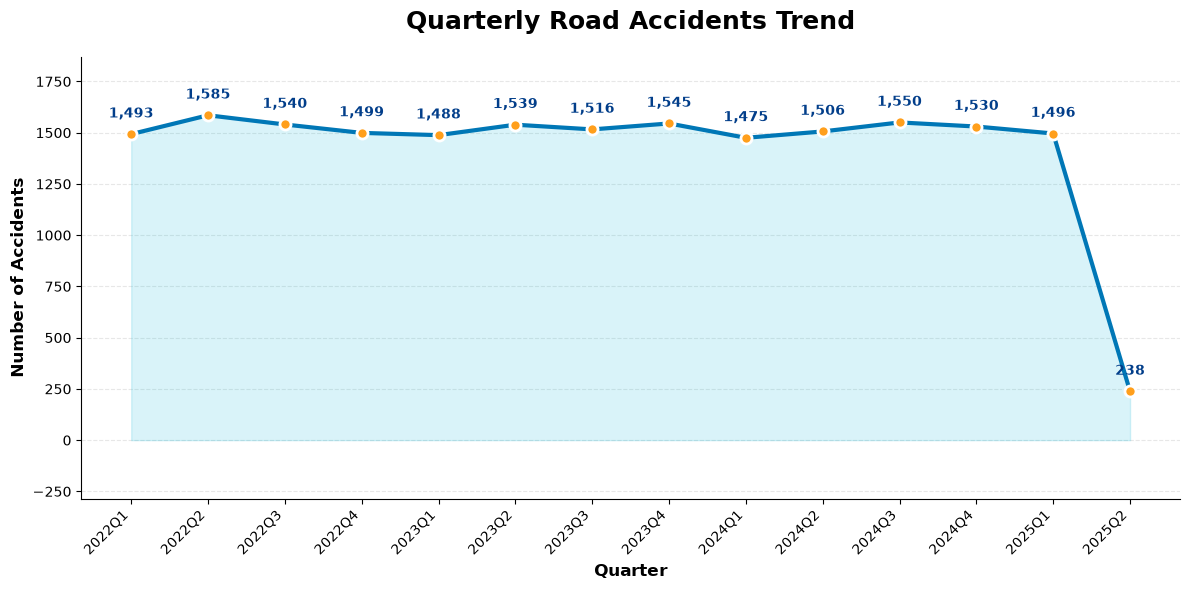

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Convert date column into datetime format
if 'df' not in globals():
    df = pd.read_csv('C:/Users/RAJPATEL/OneDrive/Desktop/-Road-safe-analytics-/indian_roads_dataset.csv')

df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Remove rows with invalid dates
df = df.dropna(subset=['date']).copy()

# Group accidents by quarter
df['Quarter'] = df['date'].dt.to_period('Q')
trend = df.groupby('Quarter').size()

# Create an attractive graph
fig, ax = plt.subplots(figsize=(12, 6))

# Plot line and markers
ax.plot(
    range(len(trend)),
    trend.values,
    color='#0077B6',
    linewidth=3,
    marker='o',
    markersize=8,
    markerfacecolor='#FF9F1C',
    markeredgecolor='white',
    markeredgewidth=2
)

# Add a light shaded area
ax.fill_between(
    range(len(trend)),
    trend.values,
    color='#00B4D8',
    alpha=0.15
)

# Display accident counts above each point
for i, value in enumerate(trend.values):
    ax.annotate(
        f'{value:,}',
        (i, value),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#023E8A'
    )

# Title and labels
ax.set_title(
    'Quarterly Road Accidents Trend',
    fontsize=18,
    fontweight='bold',
    pad=20
)
ax.set_xlabel('Quarter', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Accidents', fontsize=12, fontweight='bold')

# Format x-axis labels
ax.set_xticks(range(len(trend)))
ax.set_xticklabels(
    [str(q) for q in trend.index],
    rotation=45,
    ha='right'
)

# Improve graph appearance
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.margins(y=0.18)

plt.tight_layout()
plt.show()

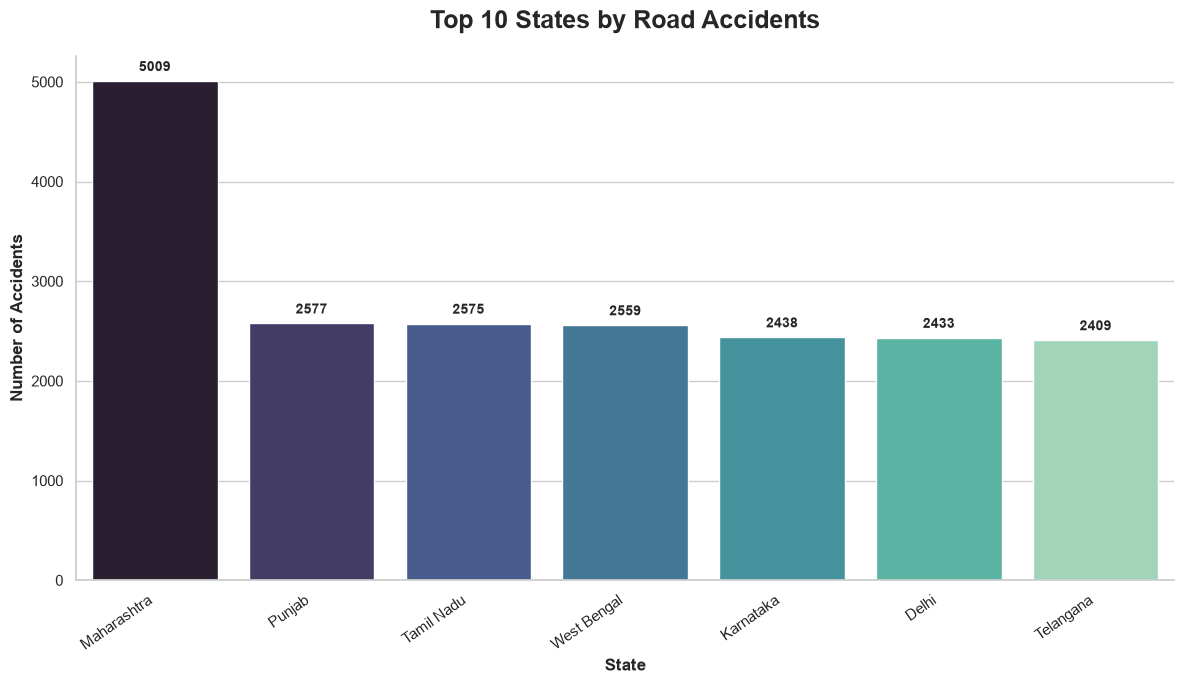

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count accidents in each state
state_counts = df['state'].value_counts().head(10)

# Create professional graph
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x=state_counts.index,
    y=state_counts.values,
    hue=state_counts.index,
    palette="mako",
    legend=False
)

# Add values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.0f',
        padding=5,
        fontsize=10,
        fontweight='bold'
    )

# Title and labels
plt.title(
    "Top 10 States by Road Accidents",
    fontsize=18,
    fontweight='bold',
    pad=20
)
plt.xlabel("State", fontsize=12, fontweight='bold')
plt.ylabel("Number of Accidents", fontsize=12, fontweight='bold')

# Improve appearance
plt.xticks(rotation=35, ha='right')
sns.despine()
plt.tight_layout()
plt.show()

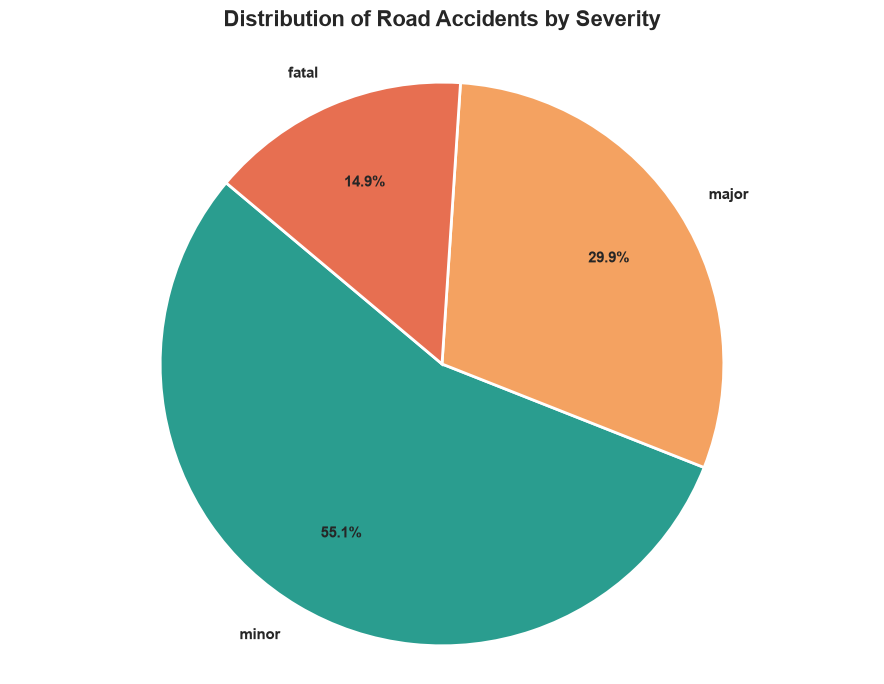

In [5]:
import matplotlib.pyplot as plt

# Count accidents by severity
severity_counts = df['accident_severity'].value_counts().dropna()

# Create pie chart
plt.figure(figsize=(9, 7))

colors = ['#2A9D8F', '#F4A261', '#E76F51', '#457B9D', '#9B5DE5']

plt.pie(
    severity_counts,
    labels=severity_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors[:len(severity_counts)],
    pctdistance=0.70,
    labeldistance=1.12,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)

# Add title
plt.title(
    'Distribution of Road Accidents by Severity',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.axis('equal')
plt.tight_layout()
plt.show()

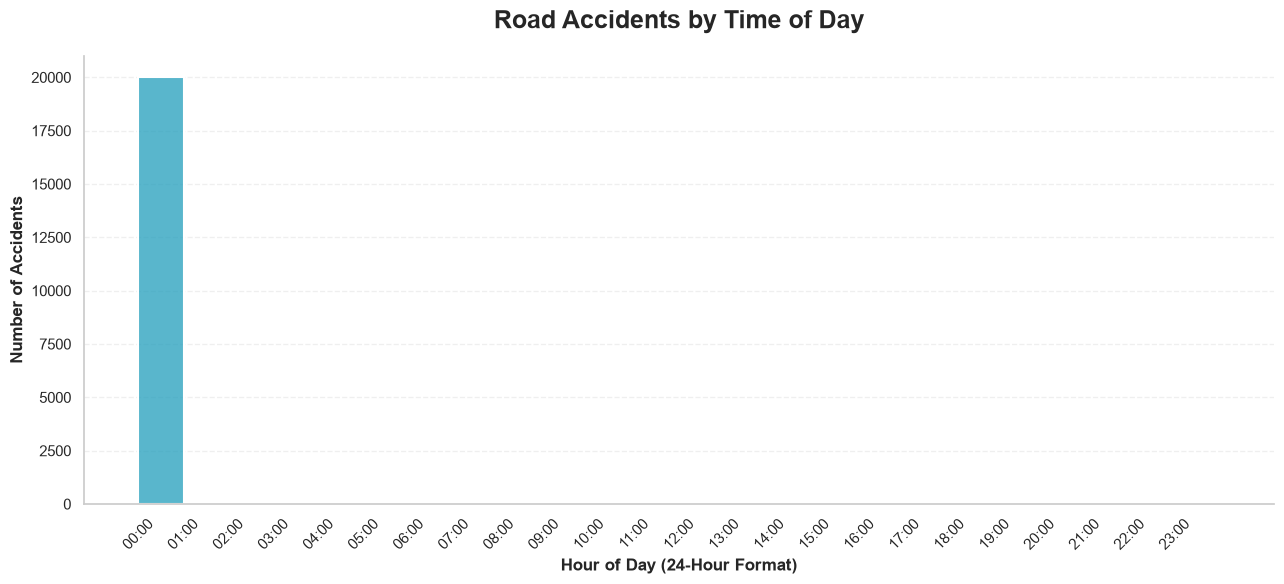

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Date column to datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Extract hour from date
df['Hour'] = df['date'].dt.hour

# Extract hour from date
df['Hour'] = df['date'].dt.hour

# Remove missing values
hours = df['Hour'].dropna()

# Set graph style
sns.set_theme(style="whitegrid")

# Create graph
fig, ax = plt.subplots(figsize=(13, 6))

sns.histplot(
    hours,
    bins=range(25),
    color='#219EBC',
    edgecolor='white',
    linewidth=1.5,
    ax=ax
)

# Add title and labels
ax.set_title(
    'Road Accidents by Time of Day',
    fontsize=18,
    fontweight='bold',
    pad=20
)
ax.set_xlabel('Hour of Day (24-Hour Format)', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Accidents', fontsize=12, fontweight='bold')

# Display all 24 hours
ax.set_xticks(range(24))
ax.set_xticklabels([f'{h:02d}:00' for h in range(24)], rotation=45)

# Improve appearance
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.grid(axis='x', visible=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

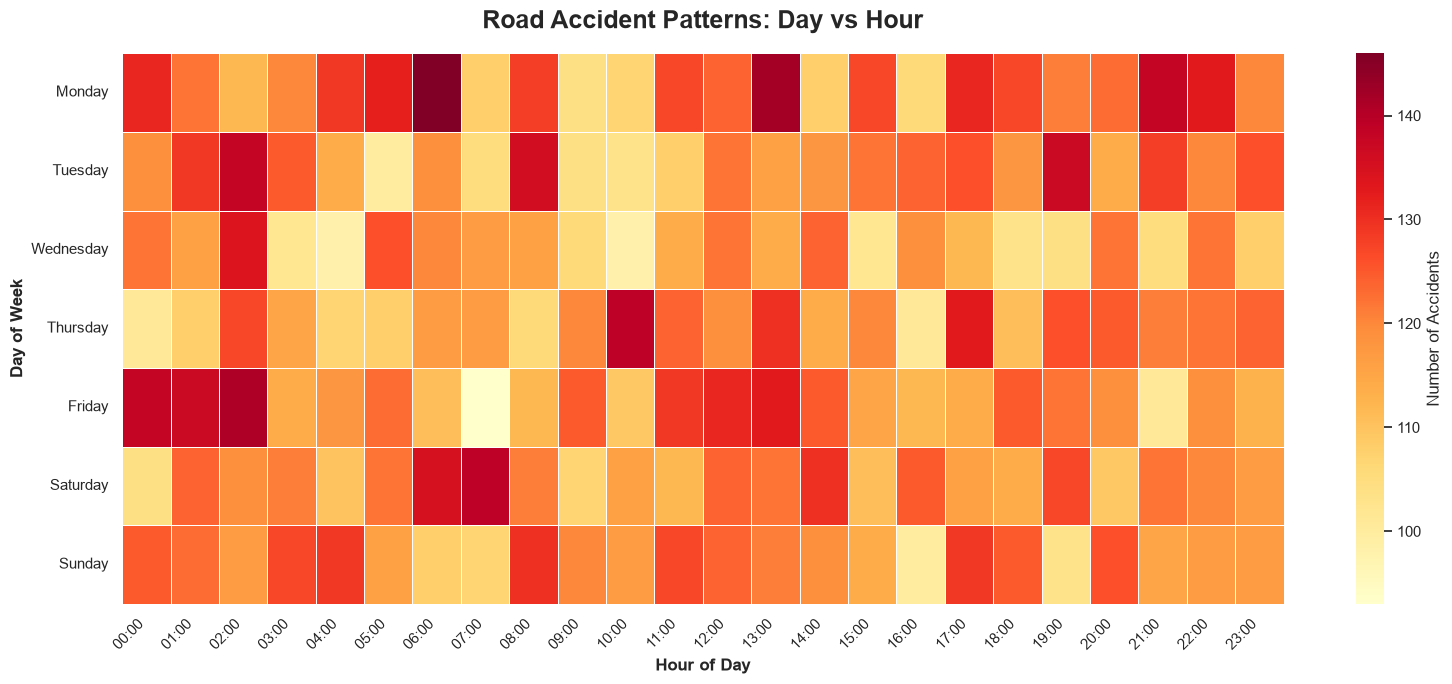

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data
data = df.copy()
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data['hour'] = pd.to_numeric(data['hour'], errors='coerce')

# Remove invalid dates and hours
data = data.dropna(subset=['date', 'hour']).copy()
data = data[data['hour'].between(0, 23)]

data['hour'] = data['hour'].astype(int)
data['DayOfWeek'] = data['date'].dt.day_name()

# Arrange weekdays
days = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

# Create heatmap data
heatmap_data = (
    data.groupby(['DayOfWeek', 'hour'])
    .size()
    .unstack(fill_value=0)
    .reindex(index=days, columns=range(24), fill_value=0)
)

# Plot ONE attractive heatmap
sns.set_theme(style='white')
fig, ax = plt.subplots(figsize=(16, 7))

sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Number of Accidents'},
    ax=ax
)

ax.set_title(
    'Road Accident Patterns: Day vs Hour',
    fontsize=18,
    fontweight='bold',
    pad=18
)
ax.set_xlabel('Hour of Day', fontsize=12, fontweight='bold')
ax.set_ylabel('Day of Week', fontsize=12, fontweight='bold')

ax.set_xticklabels(
    [f'{hour:02d}:00' for hour in range(24)],
    rotation=45,
    ha='right'
)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()